## 1. Project Topic, Direction and Research Questions

**Topic  Medical diagnosis from metadata/imaging:** AI-assisted maternal–fetal health triage using three public datasets.

| ID | Dataset | Modality | Task | Role in project |
|---|---|---|---|---|
| D1 | Maternal Health Risk | Tabular vitals | 3-class risk (low/mid/high) | Maternal risk stratification |
| D2 | Cardiotocography (CTG) | Tabular signal features | 3-class fetal state (Normal/Suspect/Pathologic) | Fetal wellbeing |
| D3 | FETAL_PLANES_DB | Ultrasound images | 6-class plane recognition | Image quality / plane verification |

TEAM MEMBERS
1. NOURIN NAWSHAD H00504162
2. NASHITAH
3. FAIZAN
4. ZAHID
5. ATHARV

Suggested research questions

- **RQ1 (D1):** Can routine maternal vitals (age, BP, blood sugar, temperature, heart rate) separate low/mid/high risk, and which features drive it?
- **RQ2 (D1, D2):** Do unsupervised methods (K-Means, GMM, Agglomerative, DBSCAN) recover the clinical risk groups without labels?
- **RQ3 (D1, D2):** Which classical model (Decision Tree, kNN, Naïve Bayes, linear/perceptron, ensembles) is best, judged by *recall on the critical class* rather than accuracy alone?
- **RQ4 (D1–D3):** Do neural networks (MLP on tabular, CNN/transfer learning on ultrasound) beat classical baselines, and at what cost in interpretability?
- **RQ5 (D1–D3):** Can the three modality-specific models be combined in a transparent late-fusion triage prototype, and what are its limits?

**Hypotheses :** H1 tree ensembles outperform linear models on D1/D2 (non-linear thresholds in vitals); H2 transfer learning outperforms a CNN trained from scratch on D3.


- Dataset papers: Ahmed & Kashem (2020) maternal risk (IoT, Bangladesh); Ayres-de-Campos et al. (2000) SisPorto CTG; Burgos-Artizzu et al. (2020) *Scientific Reports*, FETAL_PLANES_DB.
- Methods: Chawla et al. (2002) SMOTE; Tan & Le (2019) EfficientNet; Selvaraju et al. (2017) Grad-CAM; Lundberg & Lee (2017) SHAP.
- Search recent (2022–2026) work on ML for CTG classification and maternal risk prediction, so the *prior work is recent* (rubric R1-4).

## Why we chose these methods

Reference papers that shaped how we approached each dataset.

The first paper (Burgos-Artizzu et al., 2020) is where our ultrasound images
come from. They tested a lot of CNNs on exactly this plane-classification task
and found two things we took on board: starting from a network already trained
on ImageNet cut their error by a big margin, and splitting the data by patient
(not by image) is what keeps the results honest. So for the images we didn't
train a CNN from scratch — we used transfer learning with a pretrained network
and stuck to the dataset's own patient-level split. Their ~94% is the number we
measure ourselves against.

The second paper (ARMOUR) is about combining different kinds of patient data.
We can't do true fusion here because our three datasets are different people, but
it's the reason we framed the project as a triage pipeline and kept the three
modules separate and honest about that. It also sets up our future-work idea: if
the signals were ever linked to the same patients, that's the direction we'd go.

### Tabular data (maternal vitals and CTG)
These are small datasets with a handful of clear numeric features. That's the
situation where classical models tend to do best, so we lead with Logistic
Regression, Naive Bayes, k-NN, a Decision Tree, and tree ensembles (Random
Forest and Gradient Boosting). We expect the ensembles to win because risk
depends on how features interact, which trees capture well. We still train an
MLP to compare a neural network against them on the same data — and we expect it
to roughly match, not beat, the ensembles, which is a normal result for small
tabular data and worth showing rather than hiding.

### Clustering
The data is already labelled, so we're not using clustering to make labels. We
run k-means and a Gaussian Mixture Model, then check how well the clusters line
up with the real clinical classes using ARI and NMI. If they match, the risk
signal sits plainly in the features; if they don't, the labels depend on subtler
structure, which is itself a useful finding (RQ4). GMM also covers the generative
side of the coursework through the EM algorithm.

### Ultrasound images
A pretrained CNN (EfficientNet/ResNet) fine-tuned on our scans, with class
weights and light augmentation to handle the uneven plane counts. Straight from
the first paper's playbook, scaled to what free Colab GPUs can handle.

Cell 2 — Setup: mount, imports, config

In [21]:
# CELL 2 — Setup: mount Drive, imports, reproducibility, figure saving
import os, sys, random, warnings, subprocess
warnings.filterwarnings('ignore')

from google.colab import drive
drive.mount('/content/drive')
DATA = '/content/drive/MyDrive/DM&MLcsvfile'

try:
    import xlrd                                   # needed to read the old .xls CTG file
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'xlrd'])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, spearmanr

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                      cross_validate, cross_val_predict, GridSearchCV)
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import f_classif, mutual_info_classif
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression, Perceptron
from sklearn.svm import SVC
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              GradientBoostingClassifier, StackingClassifier)
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             precision_score, recall_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report,
                             silhouette_score, davies_bouldin_score,
                             adjusted_rand_score, normalized_mutual_info_score)

SEED = 42
random.seed(SEED); np.random.seed(SEED)
OUT_DIR = 'outputs'; os.makedirs(OUT_DIR, exist_ok=True)
def savefig(name):
    plt.savefig(os.path.join(OUT_DIR, name), dpi=200, bbox_inches='tight')

sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.autolayout': True})
print('Setup done.')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Setup done.


Loading the three datasets
1. MATERNAL HEALTH RISK
2. CTG
3. FETAL PLANE DATA

In [22]:
# CELL 3 — Load the three datasets
d1_raw = pd.read_csv(f'{DATA}/Maternal Health Risk Data Set.csv')
d2_raw = pd.read_excel(f'{DATA}/CTG.xls', sheet_name='Raw Data')
d3     = pd.read_csv(f'{DATA}/FETAL_PLANES_DB_data.csv', sep=';')
d3.columns = d3.columns.str.strip()          # fix trailing space in the 'Train' header

print('d1_raw:', d1_raw.shape, '| d2_raw:', d2_raw.shape, '| d3:', d3.shape)
display(d1_raw.head(3))
display(d3.head(3))

d1_raw: (1014, 7) | d2_raw: (2130, 40) | d3: (12400, 7)


,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
0,25,130,80,15.0,98.0,86,high risk
1,35,140,90,13.0,98.0,70,high risk
2,29,90,70,8.0,100.0,80,high risk


,Image_name,Patient_num,Plane,Brain_plane,Operator,US_Machine,Train
0,Patient00001_Plane1_1_of_15,1,Other,Not A Brain,Other,Aloka,1
1,Patient00001_Plane1_2_of_15,1,Other,Not A Brain,Other,Aloka,1
2,Patient00001_Plane1_3_of_15,1,Other,Not A Brain,Other,Aloka,1


Cell 4 — Clean D1 (maternal)

In [23]:
# CELL 4 — Clean D1 (maternal vitals): drop duplicates + impossible values, encode target
print('D1 missing:', int(d1_raw.isna().sum().sum()), '| duplicates:', int(d1_raw.duplicated().sum()))
d1 = d1_raw.drop_duplicates().reset_index(drop=True)      # stops identical rows landing in both train and test

bad_hr = d1['HeartRate'] < 40                             # 7 bpm is a recording error, not physiological
print('Impossible heart rates removed:', int(bad_hr.sum()))
d1 = d1[~bad_hr].reset_index(drop=True)

risk_order = ['low risk', 'mid risk', 'high risk']
d1['y'] = d1['RiskLevel'].map({name: i for i, name in enumerate(risk_order)})

D1_FEATS   = ['Age', 'SystolicBP', 'DiastolicBP', 'BS', 'BodyTemp', 'HeartRate']
D1_CLASSES = ['Low', 'Mid', 'High']
print('D1 after cleaning:', d1.shape, d1['y'].value_counts().sort_index().to_dict())

D1 missing: 0 | duplicates: 562
Impossible heart rates removed: 1
D1 after cleaning: (451, 8) {0: 233, 1: 106, 2: 112}


Cell 5 — Clean D2 (CTG)

In [24]:
# CELL 5 — Clean D2 (CTG): keep only genuine FHR features (no leakage columns), encode target
D2_FEATS = ['LB','AC','FM','UC','DL','DS','DP','DR','ASTV','MSTV','ALTV','MLTV','Width','Min',
            'Max','Nmax','Nzeros','Mode','Mean','Median','Variance','Tendency']
D2_CLASSES = ['Normal', 'Suspect', 'Pathologic']

d2 = d2_raw.dropna(subset=['NSP']).reset_index(drop=True)
print('D2 blank rows dropped:', len(d2_raw) - len(d2))
d2 = d2[D2_FEATS + ['NSP']].apply(pd.to_numeric, errors='coerce')

constant_features = [c for c in D2_FEATS if d2[c].nunique() <= 1]
print('Constant features removed:', constant_features)      # DR is all-zeros here
D2_FEATS = [c for c in D2_FEATS if c not in constant_features]
d2 = d2.drop(columns=constant_features)

n_dup = int(d2.duplicated().sum())
d2 = d2.drop_duplicates().reset_index(drop=True)
print('Duplicate recordings removed:', n_dup)

d2['y'] = d2['NSP'].astype(int) - 1                         # 1/2/3 -> 0/1/2
print('D2 after cleaning:', d2.shape, d2['y'].value_counts().sort_index().to_dict())

D2 blank rows dropped: 4
Constant features removed: ['DR']
Duplicate recordings removed: 14
D2 after cleaning: (2112, 23) {0: 1646, 1: 292, 2: 174}


Cell 6 — D3 (ultrasound metadata) prep + split check

In [25]:
# CELL 6 — D3 (ultrasound metadata): prep filenames + verify patient-level train/test split
if not str(d3['Image_name'].iloc[0]).endswith('.png'):
    d3['Image_name'] = d3['Image_name'].astype(str) + '.png'

train_patients = set(d3.loc[d3['Train'] == 1, 'Patient_num'])
test_patients  = set(d3.loc[d3['Train'] == 0, 'Patient_num'])
print('Patients in BOTH train and test (should be 0):', len(train_patients & test_patients))

print('\nImages per plane:')
print(d3['Plane'].value_counts().to_string())
assert d3['Plane'].nunique() == 6, 'expected 6 ultrasound planes'

Patients in BOTH train and test (should be 0): 0

Images per plane:
Plane
Other              4213
Fetal brain        3092
Fetal thorax       1718
Maternal cervix    1626
Fetal femur        1040
Fetal abdomen       711


## 2. Exploratory Data Analysis (R2)

Before modelling, we explore the two tabular datasets to understand their
structure and spot issues.

### Step 1 — Summary statistics
Mean, spread, range and skewness for each feature. This shows the scale of
each variable (so we know scaling is needed), and the skew column flags
heavily lopsided features.

In [26]:
# [CELL 8] Summary statistics (mean, spread, range, skewness) for the two tabular datasets
for name, df, feats in [('D1', d1, D1_FEATS), ('D2', d2, D2_FEATS)]:
    summary = df[feats].describe().T[['mean', 'std', 'min', '50%', 'max']]
    summary['skew'] = [skew(df[col]) for col in feats]
    print(f'\n{name} summary statistics')
    print(summary.round(2).to_string())


D1 summary statistics
               mean    std   min    50%    max  skew
Age           29.22  13.77  10.0   25.0   70.0  0.92
SystolicBP   110.53  17.89  70.0  120.0  160.0 -0.17
DiastolicBP   75.42  13.77  49.0   80.0  100.0 -0.03
BS             8.35   2.83   6.0    7.5   19.0  2.25
BodyTemp      98.69   1.41  98.0   98.0  103.0  1.74
HeartRate     74.10   7.53  60.0   76.0   90.0  0.04

D2 summary statistics
            mean    std    min    50%    max   skew
LB        133.30   9.83  106.0  133.0  160.0   0.02
AC          2.73   3.57    0.0    1.0   26.0   1.65
FM          7.27  37.24    0.0    0.0  564.0   9.39
UC          3.68   2.84    0.0    3.0   23.0   0.83
DL          1.58   2.50    0.0    0.0   16.0   1.81
DS          0.00   0.06    0.0    0.0    1.0  17.28
DP          0.13   0.47    0.0    0.0    4.0   4.22
ASTV       46.98  17.17   12.0   49.0   87.0  -0.01
MSTV        1.34   0.88    0.2    1.2    7.0   1.66
ALTV        9.76  18.27    0.0    0.0   91.0   2.20
MLTV       

### Step 2 — Class distributions

Check how balanced each target is across the three datasets. The level of
imbalance decides our evaluation metrics (macro-F1 and confusion matrices,
not plain accuracy) and whether we apply class weights during training.

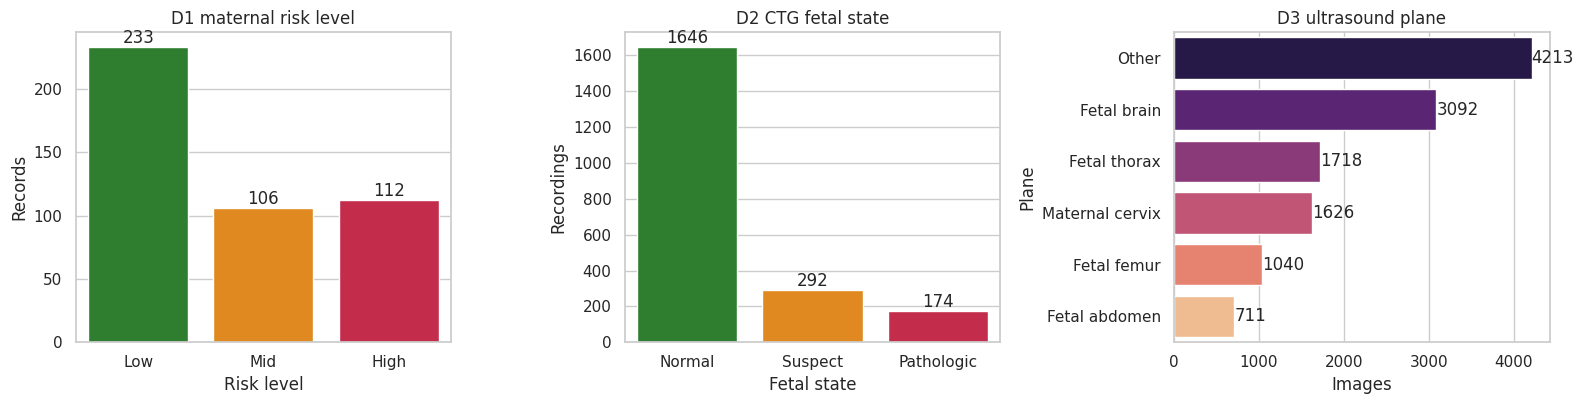

In [27]:
# [CELL 9] Class distributions of the three targets
risk_colours = ['forestgreen', 'darkorange', 'crimson']
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

sns.countplot(x=d1['y'].map(dict(enumerate(D1_CLASSES))), order=D1_CLASSES, palette=risk_colours, ax=axes[0])
axes[0].set_title('D1 maternal risk level'); axes[0].set_xlabel('Risk level'); axes[0].set_ylabel('Records')

sns.countplot(x=d2['y'].map(dict(enumerate(D2_CLASSES))), order=D2_CLASSES, palette=risk_colours, ax=axes[1])
axes[1].set_title('D2 CTG fetal state'); axes[1].set_xlabel('Fetal state'); axes[1].set_ylabel('Recordings')

sns.countplot(y=d3['Plane'], order=d3['Plane'].value_counts().index, palette='magma', ax=axes[2])
axes[2].set_title('D3 ultrasound plane'); axes[2].set_xlabel('Images'); axes[2].set_ylabel('Plane')

for ax in axes:
    for container in ax.containers:
        ax.bar_label(container)
savefig('fig_class_distributions.png'); plt.show()

All three targets are imbalanced: maternal risk is only mildly skewed, but
CTG is dominated by "Normal" and the ultrasound planes by "Other" and brain
views, with abdomen the rarest. This confirms we report macro-F1 and use
class weighting rather than relying on accuracy.

### Step 3 — Feature distributions and relation to risk (D1)

Histograms (with KDE) show the shape and skew of each maternal vital.
The boxplots show how each vital differs across risk levels — the ones
that separate the classes most are the strongest predictors (direct test
of H1: is blood sugar the strongest signal?).

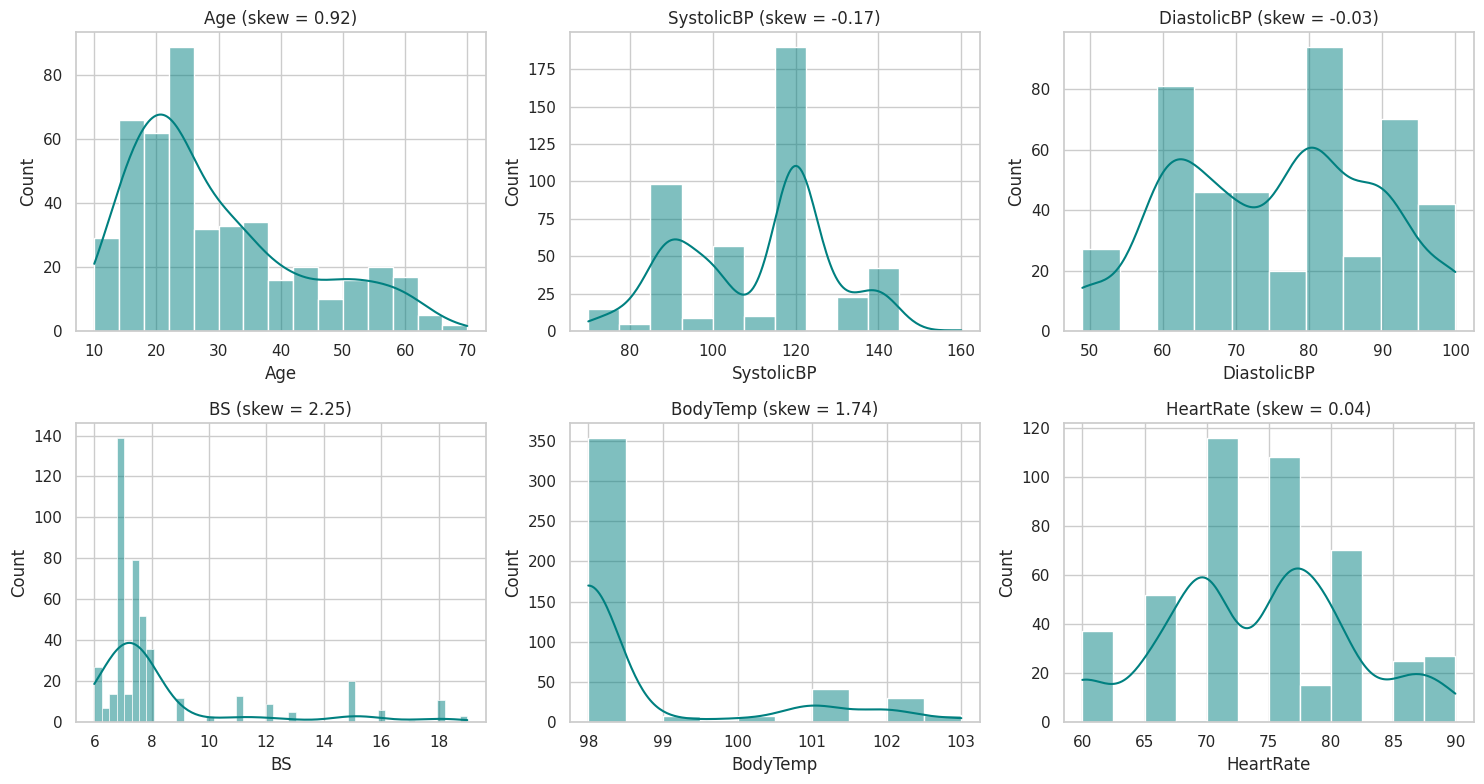

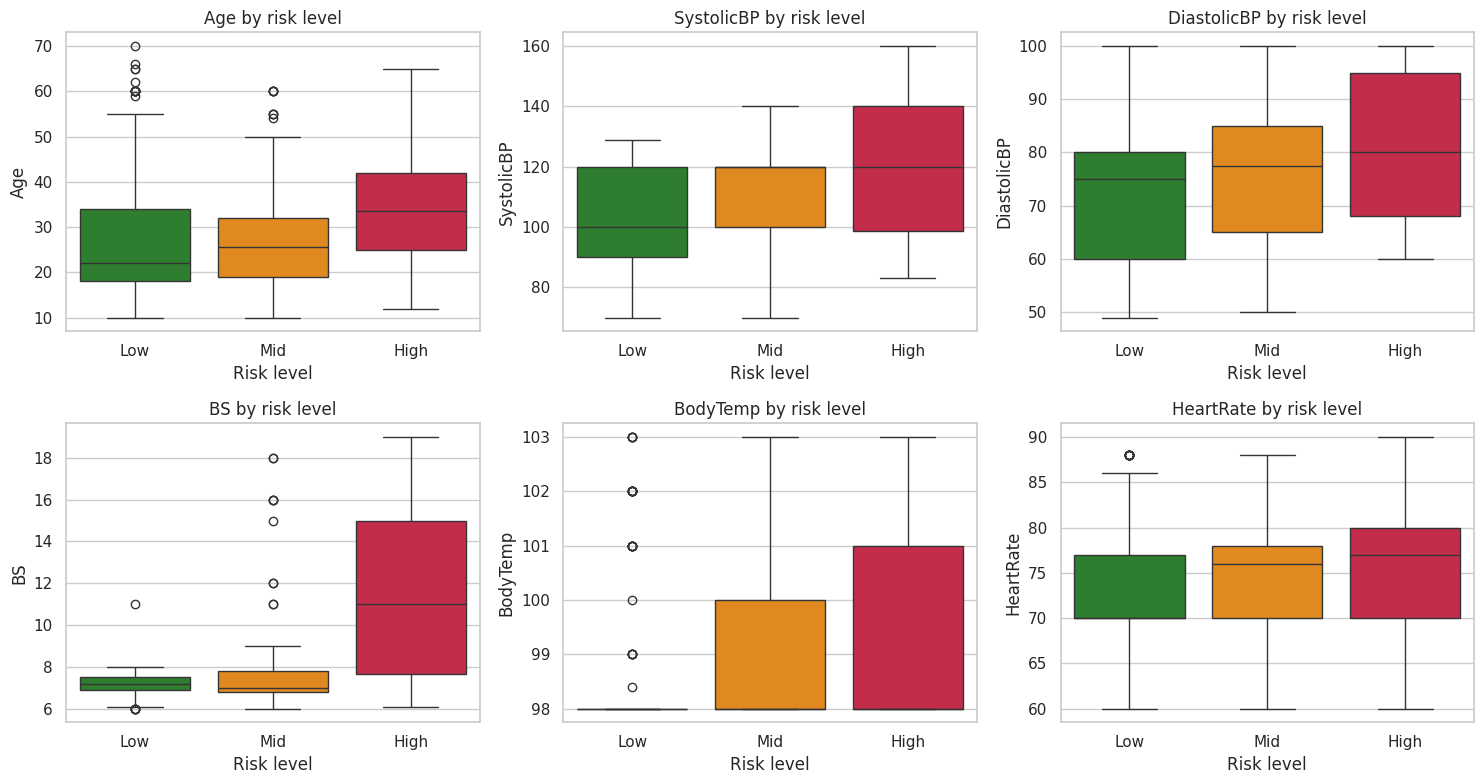

In [28]:
# [CELL 10] D1 feature distributions (histogram + density) and boxplots by risk level
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, D1_FEATS):
    sns.histplot(d1[col], kde=True, color='teal', ax=ax)
    ax.set_title(f'{col} (skew = {skew(d1[col]):.2f})'); ax.set_xlabel(col); ax.set_ylabel('Count')
savefig('fig_d1_distributions.png'); plt.show()

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, D1_FEATS):
    sns.boxplot(x=d1['y'].map(dict(enumerate(D1_CLASSES))), y=d1[col], order=D1_CLASSES, palette=risk_colours, ax=ax)
    ax.set_title(f'{col} by risk level'); ax.set_xlabel('Risk level'); ax.set_ylabel(col)
savefig('fig_d1_boxplots.png'); plt.show()

### Step 4 — Correlations and redundant features

Correlation matrices for both tabular datasets (features plus the numeric
class code `y`). Strong feature–feature correlations flag redundancy; strong
feature–`y` correlations hint at predictive power. The list below reports CTG
feature pairs with |r| > 0.9 as redundancy candidates.

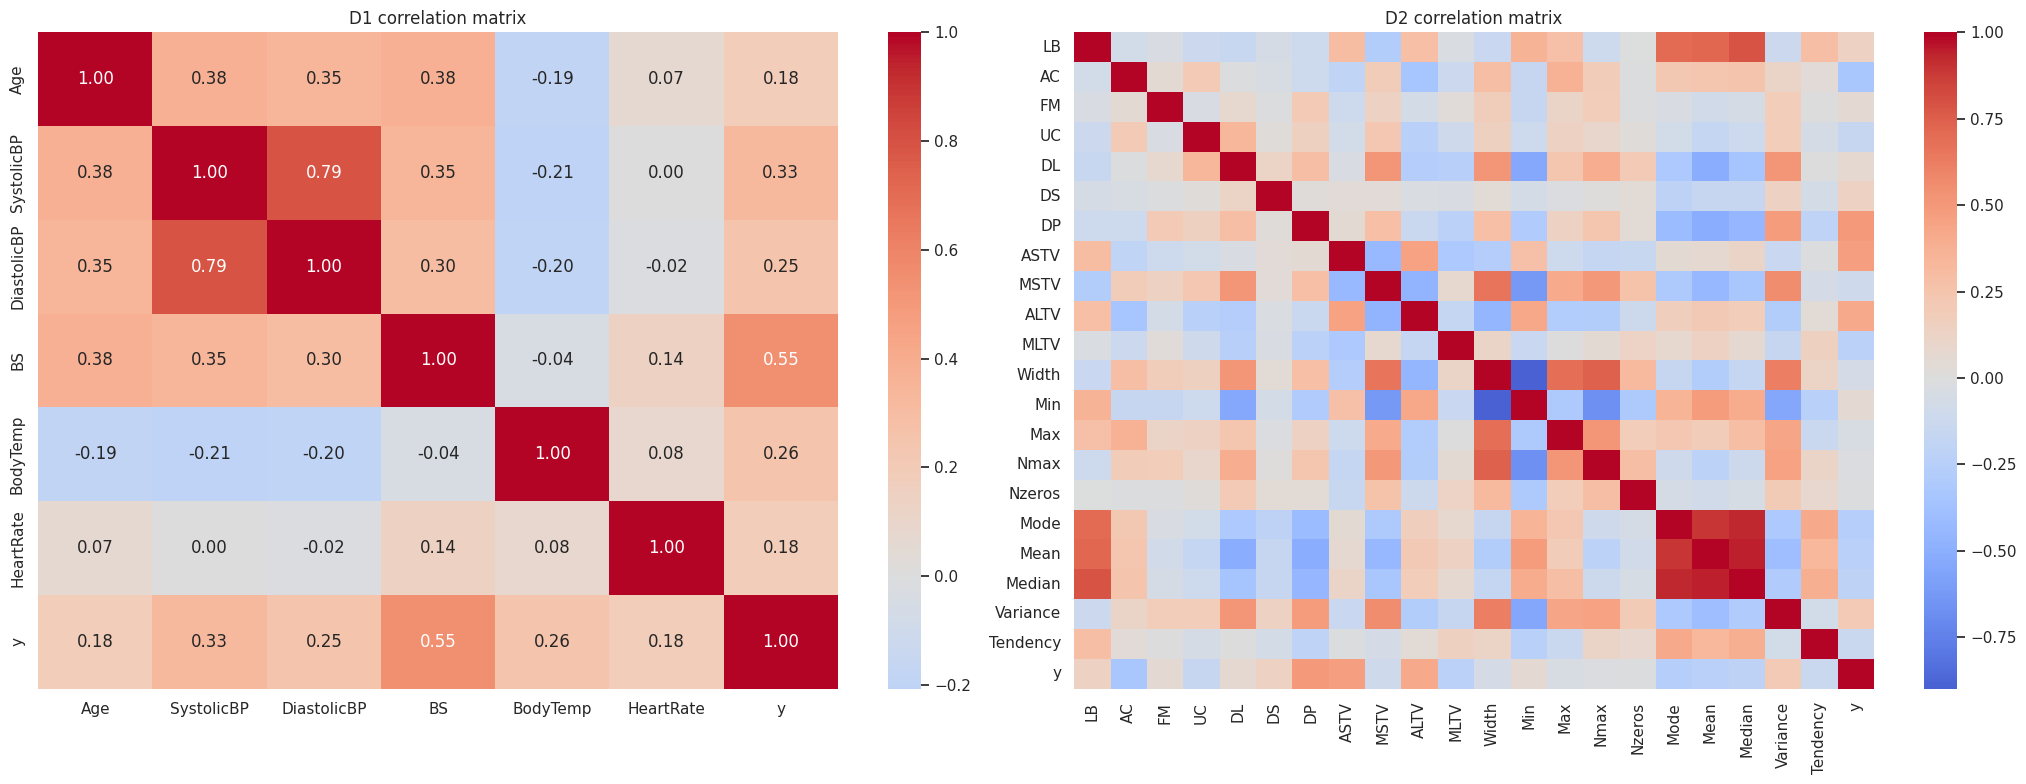

D2 feature pairs with |r| > 0.9:
Mean  Median    0.95
Mode  Median    0.93


In [29]:
# [CELL 11] Correlation matrices (y = numeric class code) and highly correlated CTG feature pairs
fig, axes = plt.subplots(1, 2, figsize=(21, 8))
sns.heatmap(d1[D1_FEATS + ['y']].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[0])
axes[0].set_title('D1 correlation matrix')
sns.heatmap(d2[D2_FEATS + ['y']].corr(), cmap='coolwarm', center=0, ax=axes[1])
axes[1].set_title('D2 correlation matrix')
savefig('fig_correlations.png'); plt.show()

corr = d2[D2_FEATS].corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
print('D2 feature pairs with |r| > 0.9:')
print(upper[upper > 0.9].sort_values(ascending=False).round(2).to_string())

### Step 5 — CTG feature separation by fetal state (D2)

Violin plots of six key CTG measurements across Normal, Suspect and
Pathologic recordings. Features where the three distributions sit apart are
the strongest signals for classifying fetal state.

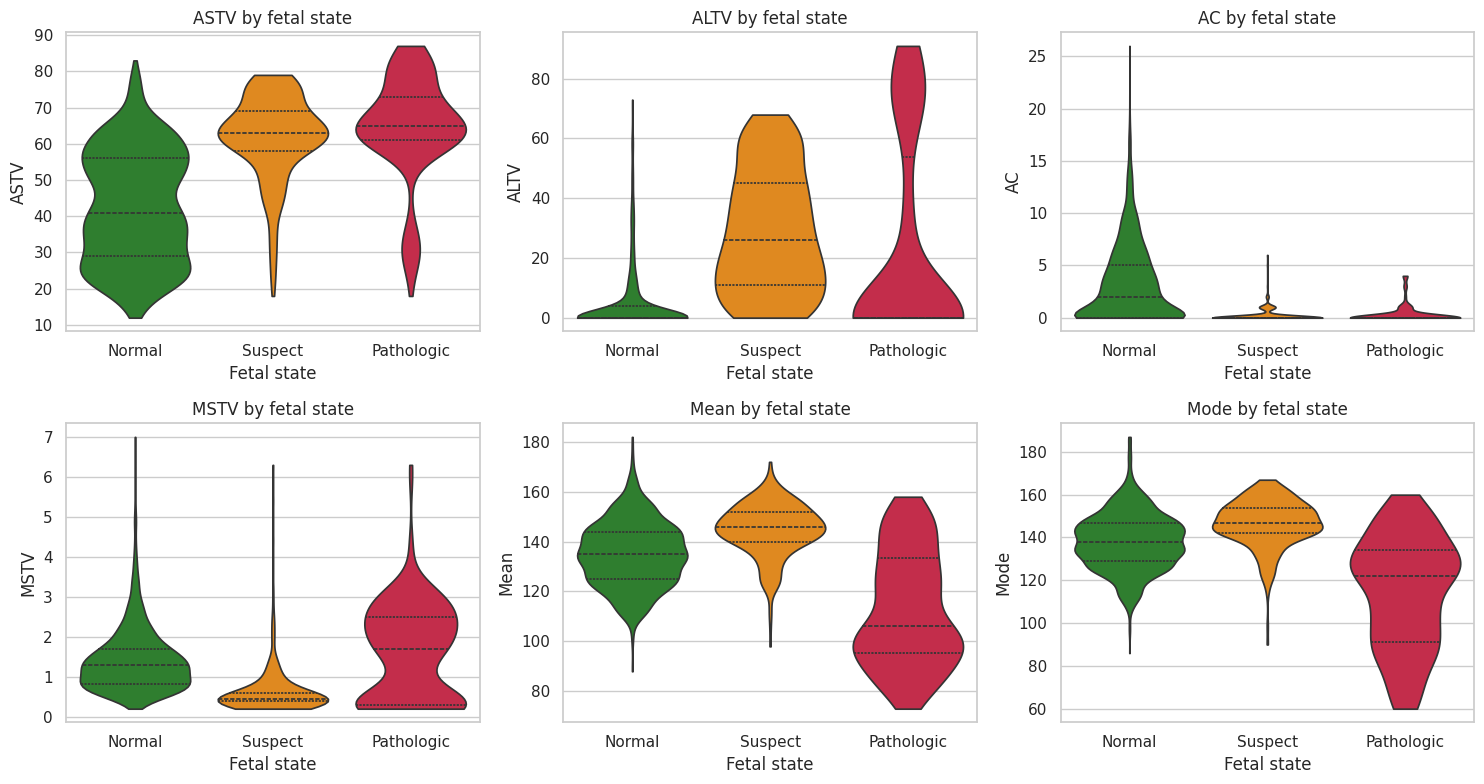

In [30]:
# [CELL 12] D2: how six CTG measurements differ between Normal, Suspect and Pathologic recordings
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, ['ASTV', 'ALTV', 'AC', 'MSTV', 'Mean', 'Mode']):
    sns.violinplot(x=d2['y'].map(dict(enumerate(D2_CLASSES))), y=d2[col], order=D2_CLASSES,
                   palette=risk_colours, inner='quartile', cut=0, ax=ax)
    ax.set_title(f'{col} by fetal state'); ax.set_xlabel('Fetal state'); ax.set_ylabel(col)
savefig('fig_d2_violins.png'); plt.show()

### Step 6 — Ultrasound image samples (D3)

One example image per plane, to show what the CNN will classify. The planes
differ visually (brain, abdomen, femur, thorax, cervix, other), which is what
makes automatic recognition feasible.

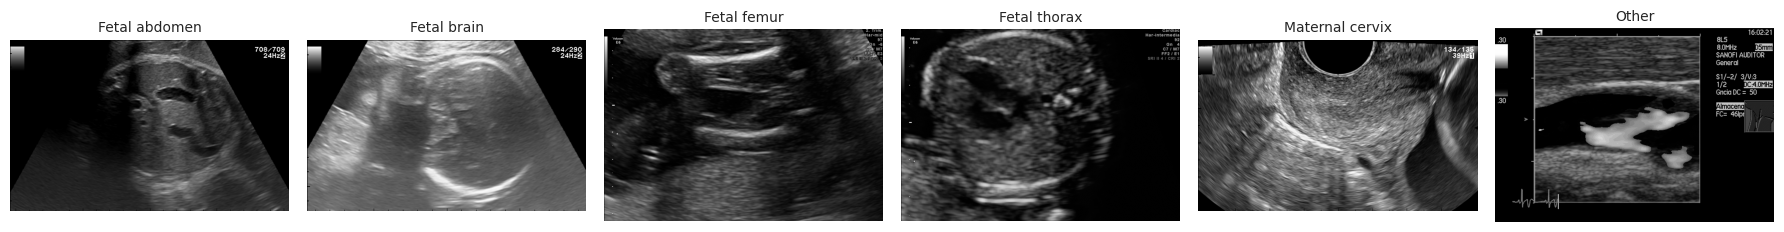

In [31]:
# Image EDA — one example per plane
IMG_DIR = '/content/drive/MyDrive/Images'

planes = sorted(d3['Plane'].unique())
fig, axes = plt.subplots(1, len(planes), figsize=(3 * len(planes), 3.4))
for ax, plane in zip(axes, planes):
    fname = d3[d3['Plane'] == plane].sample(1, random_state=SEED)['Image_name'].iloc[0]
    path = os.path.join(IMG_DIR, fname)
    if os.path.exists(path):
        ax.imshow(plt.imread(path), cmap='gray')
    ax.set_title(plane, fontsize=10); ax.axis('off')
savefig('fig_ultrasound_samples.png'); plt.show()

fetal femur and fetal thorax looks difficult to tell whereas fetal brain and detal abdomen looks similar.

### Step 7 — Feature relevance and selection

Rank each feature by three independent measures (ANOVA F-test, mutual
information, and Random Forest importance), scaled so the strongest feature
scores 1. Averaging the three gives a robust ranking. This directly tests H1
(is blood sugar the strongest maternal predictor) and tells us which CTG
features carry the signal.

D1 feature ranking
             ANOVA_F  MutualInfo  RF_importance  mean_rank
BS             1.000       1.000          1.000      1.000
SystolicBP     0.238       0.992          0.498      2.000
Age            0.075       0.504          0.431      3.667
DiastolicBP    0.146       0.302          0.319      4.000
HeartRate      0.072       0.394          0.290      5.000
BodyTemp       0.142       0.149          0.225      5.333

D2 top-10 feature ranking
          ANOVA_F  MutualInfo  RF_importance  mean_rank
ASTV        0.615       0.853          1.000      2.000
ALTV        0.612       0.879          0.831      2.667
Mean        0.554       0.791          0.722      4.000
MSTV        0.217       1.000          0.876      4.333
Mode        0.512       0.764          0.462      5.000
Median      0.463       0.686          0.412      6.333
DP          1.000       0.481          0.343      7.000
AC          0.304       0.671          0.411      7.333
Variance    0.279       0.702        

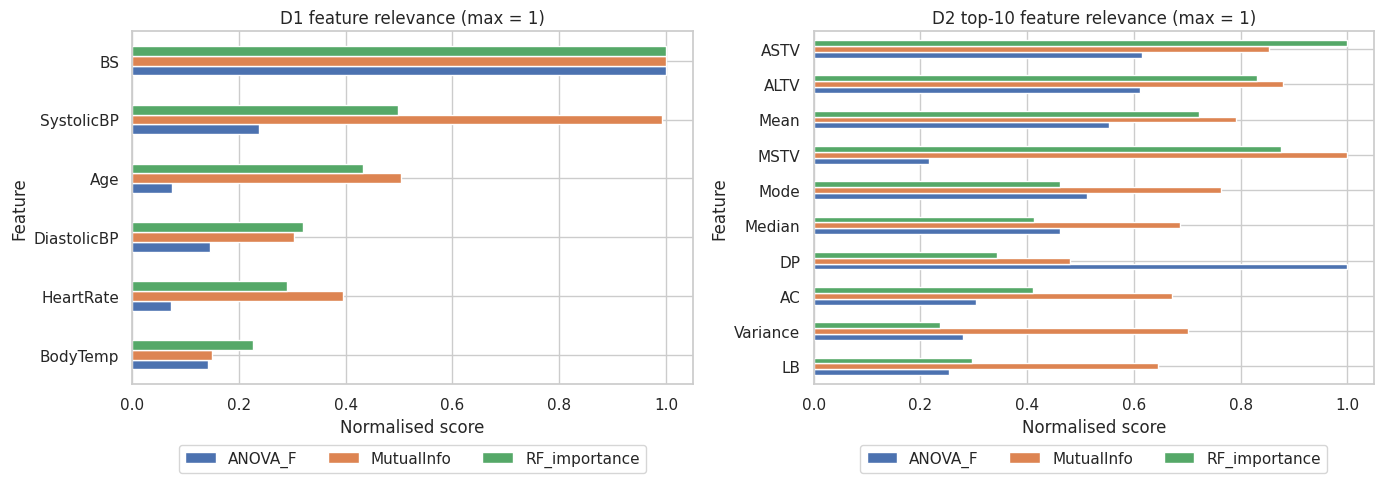

In [32]:
# [CELL 14] Feature relevance (exploration only; models use all features, so nothing leaks into the test set)
def rank_features(df, feats):
    X, y = df[feats].values, df['y'].values
    scores = pd.DataFrame(index=feats)
    scores['ANOVA_F'] = f_classif(X, y)[0]
    scores['MutualInfo'] = mutual_info_classif(X, y, random_state=SEED)
    scores['RF_importance'] = RandomForestClassifier(300, random_state=SEED).fit(X, y).feature_importances_
    scores = scores / scores.max()                                 # scale each score so the best feature = 1
    scores['mean_rank'] = scores.rank(ascending=False).mean(axis=1)
    return scores.sort_values('mean_rank')

d1_feature_rank = rank_features(d1, D1_FEATS)
d2_feature_rank = rank_features(d2, D2_FEATS)
print('D1 feature ranking'); print(d1_feature_rank.round(3).to_string())
print('\nD2 top-10 feature ranking'); print(d2_feature_rank.head(10).round(3).to_string())

score_cols = ['ANOVA_F', 'MutualInfo', 'RF_importance']
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
d1_feature_rank[score_cols].iloc[::-1].plot.barh(ax=axes[0], title='D1 feature relevance (max = 1)')
d2_feature_rank[score_cols].head(10).iloc[::-1].plot.barh(ax=axes[1], title='D2 top-10 feature relevance (max = 1)')
for ax in axes:
    ax.set_xlabel('Normalised score'); ax.set_ylabel('Feature')
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=3)
savefig('fig_feature_relevance.png'); plt.show()